Questões Conceituais


1. O processo KDD (Fayyad et al., 1996) organiza as etapas de descoberta de conhecimento. Identifique em quais etapas do KDD se encaixam as seguintes operações realizadas no notebook:



A. `pd.read_csv()`  e `df.isnull().sum()`

- Seleção (Selection): O read_csv() representa a seleção e coleta dos dados de origem, trazendo-os para o ambiente de análise.

- Pré-processamento / Limpeza (Preprocessing/Cleaning): O isnull().sum() faz parte da etapa onde identificamos anomalias, ruídos e dados faltantes (valores nulos).


B. `df.groupby('Country/Region')['Confirmed'].sum()`

- Transformação (Transformation): Esta é uma operação de agregação e sumarização. Consiste em transformar e consolidar os dados originais em formatos apropriados para a mineração.



C. `df['ObservationDate'].dt.to_period('M')`

- Transformação (Transformation): Representa a criação de novas features (Engenharia de Atributos) e redução de dimensionalidade temporal (passando de dias específicos para meses).


D. `plt.subplots(2, 3, ...)` com histogramas e boxplots

- Interpretação e Avaliação (Interpretation/Evaluation): A visualização de dados (gráficos) é a forma de interpretar os padrões descobertos, apresentar o conhecimento e permitir que o analista avalie o comportamento das variáveis. (Também transita pela etapa de Mineração através da Análise Exploratória de Dados).



2. A coluna `Province/State` apresenta 25.49% de valores ausentes. Discuta
três estratégias possíveis para tratar esses dados ausentes no contexto do
KDD e justifique qual seria a mais adequada para uma análise descritiva
geográfica da pandemia.

- Estratégia 1: Remoção da coluna inteira. Rápido, porém perderíamos toda a granularidade de estados para países gigantes como EUA, China e Austrália.

- Estratégia 2: Remoção das linhas (Dropna). Inviável, pois perderíamos 25% da base de dados, eliminando do estudo países inteiros (normalmente menores ou europeus) que simplesmente não reportam dados por província/estado.

- Estratégia 3: Imputação de dados. Preencher os valores nulos com um marcador como "Desconhecido", "Não Aplicável", ou repetir o nome do país na coluna de província.

- Justificativa: A Estratégia 3 (Imputação por "Não Aplicável" ou copiar o nome do País) é a correta. Em uma análise geográfica de pandemia, a ausência de estado não é um erro ou dado corrompido, mas sim uma característica estrutural de países unitários menores que só reportam nível nacional. Imputar mantém os registros sem jogar dados essenciais (como mortes e casos totais daquele país) no lixo.

Questões de Interpretação dos Resultados

3. O mistério dos 6 bilhões de casos confirmados nos EUA: Isso representa um erro comum na mineração de dados: aplicar uma função de agregação inadequada para a natureza do dado. O número astronômico acontece porque a coluna Confirmed no dataset da pandemia contém valores cumulativos (ou seja, a linha de hoje já tem somada os casos de ontem, de anteontem, etc.). Ao usar .sum() agrupando por país, o código está somando o total cumulativo de cada um dos dias, contando a mesma pessoa infectada centenas de vezes ao longo dos meses. Para achar o real número, deve-se pegar o valor máximo (max()) ou o registro da data mais recente reportada para o país, e não a soma de todas as datas.

4. A escolha da escala logarítmica no histograma: A pandemia tem um crescimento exponencial e apresenta uma distribuição altamente assimétrica (conhecida como Power Law ou "Cauda Longa"). Isso significa que a imensa maioria dos locais do mundo teve um volume pequeno a médio de casos, mas pouquíssimos lugares (como EUA, Índia e Brasil) tiveram dezenas de milhões de casos.

- O que aconteceria na escala linear? O gráfico seria esmagado. O eixo X (horizontal) seria esticado até dezenas de milhões por conta de um ou dois países. Quase todos os países ficariam aglomerados visualmente em uma barra única grudada no número zero (invisíveis), impossibilitando qualquer análise de distribuição das frequências. O logaritmo comprime os gigantes e expande os pequenos para vermos tudo no mesmo gráfico.

Questões Práticas de Programação


5. Função para cálculo das taxas (calcular_taxas_por_pais) Nota de implementação: Como explicamos na Questão 3, usamos o .max() para pegar o valor final acumulado da pandemia por país e não .sum().

In [7]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Certifique-se de que o arquivo "covid_19_data.csv" está na mesma pasta desse seu novo notebook.
caminho_csv = 'covid_19_data.csv'

# Carregando os dados para a variável df_kaggle
if os.path.exists(caminho_csv):
    df_kaggle = pd.read_csv(caminho_csv)
    print("Dados carregados com sucesso!")
else:
    print(f"Erro: Arquivo '{caminho_csv}' não encontrado na pasta atual.")


Dados carregados com sucesso!


In [8]:


def calcular_taxas_por_pais(df):
    # Agrupa por país e pega o valor máximo reportado (último acumulativo)
    colunas_interesse = ['Confirmed', 'Deaths', 'Recovered']
    df_agg = df.groupby('Country/Region')[colunas_interesse].max().reset_index()
    
    # Filtro: pelo menos 1000 casos confirmados
    df_agg = df_agg[df_agg['Confirmed'] >= 1000].copy()
    
    # Renomeando as colunas conforme solicitado
    df_agg = df_agg.rename(columns={
        'Confirmed': 'Total_Confirmados',
        'Deaths': 'Total_Obitos',
        'Recovered': 'Total_Recuperados'
    })
    
    # Cálculos das taxas (em porcentagem)
    df_agg['Taxa_Letalidade'] = (df_agg['Total_Obitos'] / df_agg['Total_Confirmados']) * 100
    df_agg['Taxa_Recuperacao'] = (df_agg['Total_Recuperados'] / df_agg['Total_Confirmados']) * 100
    
    # Ordenar por letalidade decrescente
    df_agg = df_agg.sort_values(by='Taxa_Letalidade', ascending=False)
    
    return df_agg

# Exemplo de uso:
# taxas_df = calcular_taxas_por_pais(df_kaggle)
# display(taxas_df.head(10))


6. Crie uma visualização que mostre a **média móvel de 7 dias** dos novos casos confirmados globais. Dica: o dataset traz valores cumulativos — será necessário calcular a diferença diária antes de aplicar a média móvel.`.


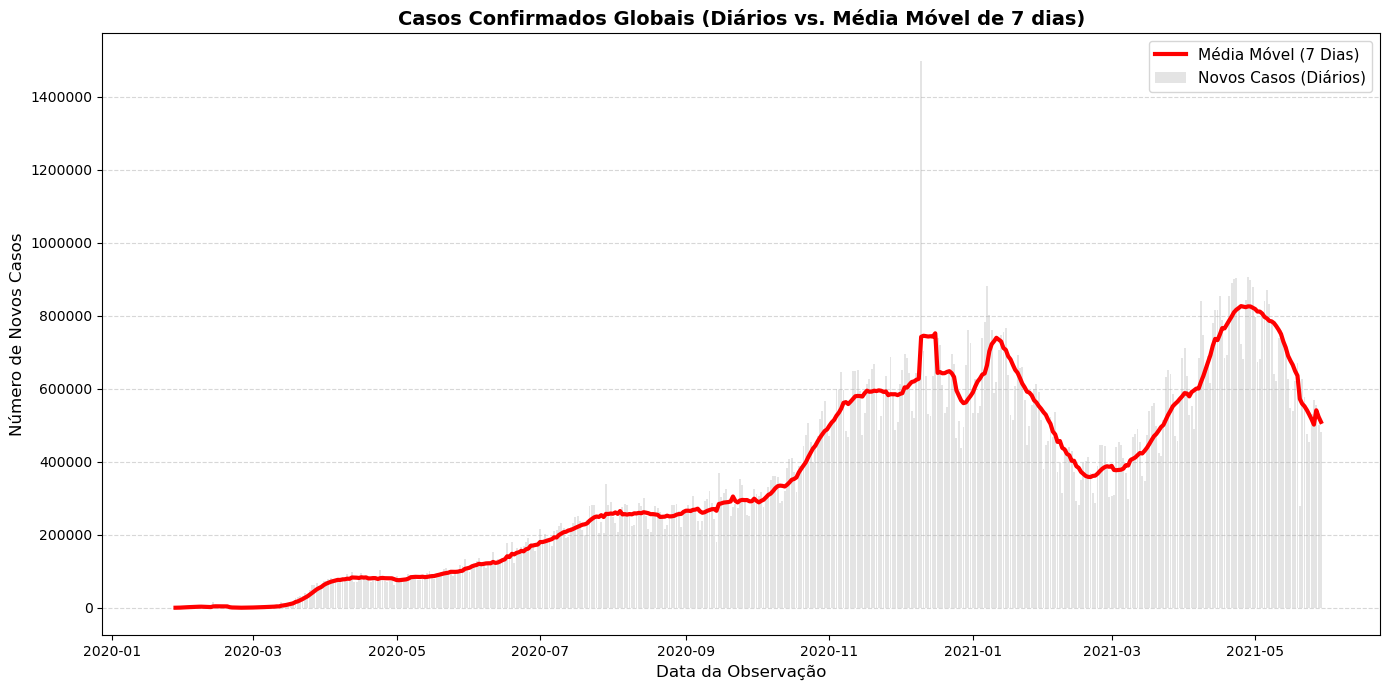

In [9]:

# 1. Garantir que a data é do tipo datetime
df_kaggle['ObservationDate'] = pd.to_datetime(df_kaggle['ObservationDate'])

# 2. Agrupar os valores cumulativos totais do MUNDO por dia
# Nota: como por província é acumulado, somar tudo no mesmo dia dá o total mundial acumulado daquele dia
casos_mundiais_acumulados = df_kaggle.groupby('ObservationDate')['Confirmed'].sum().sort_index()

# 3. Calcular novos casos por dia usando diferença (.diff()) e remover o dia 1 que fica nulo
novos_casos_diarios = casos_mundiais_acumulados.diff().fillna(0)

# 4. Calcular a média móvel de 7 dias
media_movel_7d = novos_casos_diarios.rolling(window=7).mean()

# 5. Criar a visualização
plt.figure(figsize=(14, 7))

# Gráfico de barras sutis ou linha para os casos diários reais (com variação/ruído diário)
plt.bar(novos_casos_diarios.index, novos_casos_diarios.values, 
        label='Novos Casos (Diários)', color='lightgray', alpha=0.6)

# Linha da média móvel 
plt.plot(media_movel_7d.index, media_movel_7d.values, 
         label='Média Móvel (7 Dias)', color='red', linewidth=3)

# Embelezamento do gráfico
plt.title('Casos Confirmados Globais (Diários vs. Média Móvel de 7 dias)', fontsize=14, fontweight='bold')
plt.xlabel('Data da Observação', fontsize=12)
plt.ylabel('Número de Novos Casos', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Evitar formato científico nos eixos
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()


7. O dataset possui valores negativos em algumas colunas (visíveis no `describe()` — mínimo de -302844 em `Confirmed`). Escreva um código que:

A. identifique todos os registros com valores negativos

B. investigue se são erros de digitação ou ajustes epidemiológicos

C. proponha e implemente uma estratégia de correção

A. Código para identificar os registros:

In [10]:
# Selecionamos as colunas onde os valores negativos não deveriam existir (já que são acumulativos)
colunas_analise = ['Confirmed', 'Deaths', 'Recovered']

# Cria uma máscara para encontrar qualquer linha que tenha valor < 0 em alguma das 3 colunas
mascara_negativos = (df_kaggle[colunas_analise] < 0).any(axis=1)

# Filtra o DataFrame
df_negativos = df_kaggle[mascara_negativos]

print(f"Total de registros com valores negativos: {len(df_negativos)}")
display(df_negativos.head()) # Exibe os primeiros casos encontrados


Total de registros com valores negativos: 4


,SNo,ObservationDate,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
118363,118364,2020-09-24,Unknown,Colombia,2021-04-02 15:13:53,0.0,-178.0,-12684.0
141534,141535,2020-10-25,Unknown,Colombia,2021-04-02 15:13:53,0.0,-154.0,-8072.0
145277,145278,2020-10-30,Unknown,Colombia,2021-04-02 15:13:53,0.0,505.0,-854405.0
147524,147525,2020-11-02,Unknown,Colombia,2021-04-02 15:13:53,-302844.0,0.0,0.0


B. investigue se são erros de digitação ou ajustes epidemiológicos

- Em datasets epidemiológicos (como os da Universidade Johns Hopkins), valores "negativos" ou quedas bruscas irreais em contagens acumulativas geralmente não são erros de digitação simples, mas sim ajustes/auditorias retrospectivas. Se um Ministério da Saúde descobre que contou 300.000 casos duplicados ao longo de meses, eles frequentemente aplicam uma subtração gigantesca em um único dia para que o saldo total fique correto, gerando essas anomalias estatísticas no dia do ajuste.

C. proponha e implemente uma estratégia de correção

- Como não faz sentido conceitual existir um saldo "negativo" de pessoas totais confirmadas ou mortas, a abordagem de correção mais robusta seria usar o valor da mesma região no dia anterior (interpolação/Forward Fill). Porém, de forma rápida para não quebrar agregações simples, podemos limitar o valor inferior a zero (clip).

In [11]:
# Implementação da correção limitando o piso matemático a 0
df_kaggle_limpo = df_kaggle.copy()

for coluna in colunas_analise:
    # A função clip garante que qualquer número menor que 0 vire 0
    df_kaggle_limpo[coluna] = df_kaggle_limpo[coluna].clip(lower=0)

# Validação:
print("Verificando se ainda existem valores negativos:")
print((df_kaggle_limpo[colunas_analise] < 0).sum())


Verificando se ainda existem valores negativos:
Confirmed    0
Deaths       0
Recovered    0
dtype: int64


Questões Integradoras (KDD + Análise)


8. Três novas features (Engenharia de Atributos/Transformação)

1. Casos_Ativos (Confirmed - (Deaths + Recovered)):
- Agregação de Valor: O número de confirmados sempre cresce, mas os Casos Ativos mostram a verdadeira curva da pandemia (quando sobe e quando desce). É a variável mais importante preditivamente para estimar o risco de colapso do sistema de saúde hospitalar em um dado momento.

2. Dias_Desde_O_Primeiro_Caso:
- Agregação de Valor: Transforma o calendário em uma "linha do tempo relativa". Isso permite que um modelo de Machine Learning compare a curva epidemiológica (ex: "dia 40 da pandemia na Itália" vs "dia 40 no Brasil"), essencial para previsões generalizáveis independentemente de quando o vírus chegou ao país.

3. Taxa_de_Crescimento_Diario (Variação Percentual):
- Agregação de Valor: Representa a aceleração do contágio (análogo ao número de reprodução Rt). É fundamental para algoritmos preditivos temporais entenderem se a pandemia está perdendo força ou entrando em crescimento exponencial antes mesmo do volume absoluto estourar.

9. Considerando que o notebook é apenas a etapa descritiva do KDD,descreva em um parágrafo quais seriam as próximas etapas para evoluir essa análise até uma **Análise Preditiva**, mencionando algoritmos apropriados e métricas de avaliação.

- Próximas etapas para evolução até uma Análise Preditiva Até agora, passamos pelas etapas de Limpeza, Transformação e Mineração (Análise Exploratória) para olhar o passado. Para evoluir para a Análise Preditiva, a próxima etapa do KDD seria a modelagem propriamente dita. Teríamos que dividir o dataset de forma cronológica (série temporal) em dados de treino e teste. Em seguida, treinaríamos algoritmos de séries temporais (como ARIMA, Prophet do Facebook, ou Redes Neurais recorrentes como LSTM). A etapa final seria a Avaliação (Evaluation), onde testaríamos as previsões do modelo contra os dias reais do passado usando métricas de erro como RMSE (Raiz do Erro Quadrático Médio) ou MAPE (Erro Percentual Absoluto Médio), validando se o modelo é confiável antes de tentar prever o futuro.

10. O script original usa a API do Kaggle via `userdata.get()` do Colab.Discuta os cuidados de segurança envolvidos no uso de credenciais em notebooks compartilhados e proponha uma alternativa para tornar o código reprodutível sem expor tokens.

- Segurança no compartilhamento de credenciais Deixar tokens, chaves e senhas escritos diretamente (hardcoded) no notebook, como os.environ['KAGGLE_KEY'] = 'minha_senha123', é um risco cibernético altíssimo. Se o notebook for colocado no GitHub, bots raspadores roubam a credencial em segundos, podendo gerar custos na sua nuvem ou vazar dados de empresas.

- Cuidados: O Colab usa o gerenciador de "Secrets" (o ícone de chave) para injetar as senhas apenas no servidor na hora de rodar, sem salvá-las no texto do código.

- Alternativa Reprodutível Local: A alternativa oficial da comunidade Python é o uso de um arquivo .env invisível. Usando a biblioteca python-dotenv, cada pessoa cria um arquivo chamado .env (onde coloca suas próprias senhas) na sua máquina e o marca no arquivo .gitignore para o git nunca rastreá-lo. O código do notebook apenas chama load_dotenv() e acessa a chave de forma segura e padronizada. Outra solução, nativa para esse caso, é configurar o arquivo oficial kaggle.json no diretório de usuário (ex: ~/.kaggle/), conforme exige a API padrão.